In [3]:
import lorislab as ll
import itertools
import pandas as pd
from lorislab import xp
from lorislab.fuzzylogic import DSRegressor
from lorislab.fuzzylogic import mixed_metric, r2
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, r2_score

RANDOM_STATE = 88888888
DARK_MODE = True

ModuleNotFoundError: No module named 'lorislab'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Wemds by invpy

### Preparazione datasets 1000 dati

In [3]:
def dataset_ready(N, lim_sx=-2, lim_dx=2, n_features=3):

    N_FEATURES = 3
    def _out_func(x1,x2,x3):
        return x1**2 + ( (0.7*x2) / (xp.abs(x3)+1) )

    X = xp.random.randn(N,N_FEATURES)*(lim_dx-lim_sx)
    Y = _out_func(X[:,0],X[:,1],X[:,2]).reshape(-1,1)
    
    df = xp.hstack((X,Y))
    
    return df

### Funzione per ottenere i risultati

In [4]:
def res_graph(model, df_test, to_round = False):
    y_out = model.predict(df_test[:,:-1])
    y_true = df_test[:,-1]
    idx = xp.arange(len(y_out))
    fig, ax = invpy.graph(idx, y_true,"idx","true", graph_type="lollipop")
    if to_round:
        _ = invpy.graph(idx, xp.round(y_out),"idx","outs", graph_type="lollipop", ax=ax)
    else:
        _ = invpy.graph(idx, y_out,"idx","outs", graph_type="lollipop", ax=ax)
        
    print("Accuracy: ", accuracy_score(y_true, xp.round(y_out).get()))
    print("Precision (weighted): ", precision_score(y_true, xp.round(y_out).get(), average="weighted"))
    print("Precision (macro): ", precision_score(y_true, xp.round(y_out).get(), average="macro"))

In [5]:
xp.random.seed(RANDOM_STATE) # Reproducibility of code
print(invpy.is_gpu_backend())
df_train = dataset_ready(1000)
df_test = dataset_ready(100)
df_val = dataset_ready(100)

True


### WEMDS routines

In [6]:
ml_model_1 = WEMDS(fuzzy_output=True, fire_of_train_rules=False)
ml_model_1.fit_cross_validation(df_train, df_val, n_of_sets=6)

|----> Starting Global Optimization 
|----> New best score with n_of_sets: [6 6 6 6] -> Scored: 0.7385089986788841
|----> New best score with n_of_sets: [5 5 5 5] -> Scored: 0.741393363788325
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 5 5 5] -> Scored: 0.7921056082322897
|--------> New best score with n_of_sets: [6 4 5 5] -> Scored: 0.8427635465342878
|--------> New best score with n_of_sets: [6 4 4 5] -> Scored: 0.8648943110245948
|--------> New best score with n_of_sets: [6 4 4 6] -> Scored: 0.8787847942936061
|--------> New best score with n_of_sets: [7 4 4 6] -> Scored: 0.9026600724686373
|--------> New best score with n_of_sets: [7 4 4 7] -> Scored: 0.9090907387776559
|--------> New best score with n_of_sets: [8 4 4 7] -> Scored: 0.9213377751379225
|--------> New best score with n_of_sets: [8 3 4 7] -> Scored: 0.9310052767869151
|--------> New best score with n_of_sets: [8 3 4 8] -> Scored: 0.9352308932847
|--------> New best sco

In [7]:
len(ml_model_1.Rules)

78

In [8]:
y_out = ml_model_1.predict(df_test[:,:-1])
y_true = df_test[:,-1]
print(r2(y_out,y_true))

0.9798654863149111


# Functions

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_openml
import numpy as np
import pandas as pd

# Assuming 15% dimension of val e test
val_perc = 15/100
test_perc = 15/85

def load_dataset_and_split(
    uci_id,
    test_size=test_perc,
    val_size=val_perc,
    random_state=RANDOM_STATE,
    shuffle = True,
):
    """
    Carica un dataset UCI tramite ID (via OpenML) e restituisce
    train, validation e test set con stratificazione automatica.
    """
    # --- 1. Caricamento dataset da UCI/OpenML ---
    data = fetch_openml(data_id=uci_id, as_frame=False)

    X = data.data
    y = data.target

    # Determina se è classificazione
    # (target non numerico → classificazione)
    is_classification = not np.issubdtype(y.dtype, np.number)

    # Se classificazione, converte le classi in numeri
    if is_classification:
        _, y = np.unique(y, return_inverse=True)

    # --- 2. Costruzione array finale ---
    df = np.column_stack([X, y])


    # --- 3. Train/Test split ---
    strat = y if is_classification else None

    df_train, df_test = train_test_split(
        df,
        test_size=test_size,
        shuffle=shuffle,
        random_state=random_state,
        stratify=strat
    )

    # --- 4. Train/Validation split ---
    y_train = df_train[:, -1]
    strat2 = y_train if is_classification else None

    df_train, df_val = train_test_split(
        df_train,
        test_size=val_size,
        shuffle=shuffle,
        random_state=random_state,
        stratify=strat2
    )

    return df_train, df_val, df_test


In [10]:
def generate_configurations(unique_list):
    """
    Generate all 8 combinations of DSI flags.

    parameters
    ----------
    unique_list: list
        List of bool: True where operator forces the division of feature domain
        on the unique values contained. False where the approach follows density
        based or linear feature domain division.

    returns
    -------
    configs: dict
        Various configuration to test the model.
    """

    configs = []

    fire_options = [True, False]
    fuzzy_options = [True, False]
    db_options = [True, False]

    for fire, fuzzy, db in itertools.product(fire_options, fuzzy_options, db_options):

        # Base division depending on DB flag
        if db:
            division = ["D"] * len(unique_list)
        else:
            division = ["L"] * len(unique_list)

        # Enforce class-based division
        for i, is_unique in enumerate(unique_list):
            if is_unique:
                division[i] = "U"

        configs.append({
            "fire_of_train_rules": fire,
            "fuzzy_output": fuzzy,
            "default_division": division,
        })

    return configs

def paper_test(df_train, df_val, df_test, configurations):

    results = []

    for config in configurations:

        print("Starting optimizzation for:\n",config)
        
        model = WEMDS(**config)
        model.fit_cross_validation(df_train, df_val)

        # --- Predizione ---
        y_out = model.predict(df_test[:, :-1])
        y_true = df_test[:, -1]
        y_pred = y_out.get()

        # --- Gestione predizioni mancanti ---
        valid_mask = ~np.isnan(y_pred)
        cov = valid_mask.mean()   # coverage

        if valid_mask.sum() == 0:
            y_pred_valid = np.array([])
            y_true_valid = np.array([])
        else:
            y_pred_valid = y_pred[valid_mask]
            y_true_valid = y_true[valid_mask]

        # --- Entry base ---
        entry = {
            "fire_of_train_rules": config["fire_of_train_rules"],
            "fuzzy_output": config["fuzzy_output"],
            "default_division": config["default_division"],
            "task": model.task,
            "cov": cov
        }

        # --- Score ---
        if model.task == "classification":
            if len(y_pred_valid) > 0:
                entry["acc"] = accuracy_score(y_true_valid, y_pred_valid)
                entry["pre"] = precision_score(y_true_valid, y_pred_valid, average="macro")
            else:
                entry["acc"] = np.nan
                entry["pre"] = np.nan

        else:  # regression
            if len(y_pred_valid) > 0:
                entry["r2"] = r2_score(y_true_valid, y_pred_valid)
            else:
                entry["r2"] = np.nan

        results.append(entry)

    return results


In [11]:
import pandas as pd
import pyperclip

def from_res_to_table(results):
    df_results = pd.DataFrame(results)

    # Ensure columns exist
    for col in ["acc", "pre", "cov", "r2"]:
        if col not in df_results.columns:
            df_results[col] = np.nan

    # Add DB / ER / HF columns
    df_results["DB"] = df_results["default_division"].apply(lambda x: "D" if x[0] == "D" else "L")
    df_results["ER"] = df_results["fuzzy_output"].map({True: "ON", False: "OFF"})
    df_results["HF"] = df_results["fire_of_train_rules"].map({True: "ON", False: "OFF"})
    df_results["cov"] = df_results["cov"].astype(float)

    # Summary (classification or regression)
    if df_results["task"].iloc[0] == "classification":
        df_summary = df_results[["DB", "ER", "HF", "acc", "pre", "cov"]]
    else:
        df_summary = df_results[["DB", "ER", "HF", "r2", "cov"]]

    # Round numeric columns
    df_summary = df_summary.round(2)

    # Sort by main score
    score_col = "acc" if "acc" in df_summary.columns else "r2"
    df_summary = df_summary.sort_values(score_col, ascending=False).reset_index(drop=True)

    # Copy to clipboard
    pyperclip.copy(df_summary.to_csv(index=False, sep="\t"))

    return df_summary


## IRIS

In [197]:
df_train_1, df_val_1, df_test_1 = load_dataset_and_split(61)
df_train_1.shape

(104, 5)

In [198]:
class_list_1 = [False]*4 + [True] # Last only is a class

In [199]:
configs_1 = generate_configurations(class_list_1)

In [200]:
result_1 = paper_test(df_train_1, df_val_1, df_test_1, configs_1)

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': True, 'default_division': ['D', 'D', 'D', 'D', 'C'], 'task': 'classification'}
['D', 'D', 'D', 'D', 'C']
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 5 5 3] -> Scored: 0.9227642276422764
|----> New best score with n_of_sets: [4 4 4 4 3] -> Scored: 1.0
|--------> Starting Coordinate-wise Optimization 
|------------> Cross-validation ended succesfully:
|------------> [4 4 4 4 3] -> Best number of set per feature
|------------> 1.0 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': True, 'default_division': ['L', 'L', 'L', 'L', 'C'], 'task': 'classification'}
['L', 'L', 'L', 'L', 'C']
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 5 5 3] -> Scored: 0.9227642276422764
|----> New best score with n_of_sets: [4 4 4 4 3] -> Scored: 1.0
|--------> Starting Coordinate-wise Optimizati

In [201]:
from_res_to_table(result_1)

,DB,ER,HF,acc,pre,cov
0,L,ON,ON,1.00,1.00,1.00
1,L,ON,OFF,0.96,0.97,1.00
2,D,ON,ON,0.93,0.93,1.00
3,D,OFF,ON,0.92,0.92,0.93
4,D,OFF,OFF,0.92,0.92,0.93
5,L,OFF,ON,0.89,0.92,1.00
6,D,ON,OFF,0.89,0.89,1.00
7,L,OFF,OFF,0.89,0.92,1.00


## AIRFOIL SELF NOISE

Id on OpenML = 44957

In [30]:
df_train_2, df_val_2, df_test_2 = load_dataset_and_split(44957)
df_train_2.shape

(1051, 6)

In [31]:
class_list_2 = [False]*2 + [True]*2 + [False]*2 # There're no class data
configs_2 = generate_configurations(class_list_2)
result_2 = paper_test(df_train_2, df_val_2, df_test_2, configs_2)

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': True, 'default_division': ['D', 'D', 'C', 'C', 'D', 'D'], 'task': 'regression'}
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 6 4 5 5] -> Scored: 0.6830662773706758


C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|----> New best score with n_of_sets: [6 6 6 4 6 6] -> Scored: 0.7618102174471456
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 6 6 4 5 6] -> Scored: 0.7661098068191805
|------------> Cross-validation ended succesfully:
|------------> [6 6 6 4 5 6] -> Best number of set per feature
|------------> 0.7661098068191805 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': True, 'default_division': ['L', 'L', 'C', 'C', 'L', 'L'], 'task': 'regression'}
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 6 4 5 5] -> Scored: 0.6094941321265203
|----> New best score with n_of_sets: [6 6 6 4 6 6] -> Scored: 0.6377416914051812
|----> New best score with n_of_sets: [7 7 6 4 7 7] -> Scored: 0.6590428893111706
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [8 7 6 4 7 7] -> Scored: 0.6636126850717537
|--------> 

C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|----> New best score with n_of_sets: [6 6 6 4 6 6] -> Scored: 0.6905038240343385
|----> New best score with n_of_sets: [7 7 6 4 7 7] -> Scored: 0.7204819117342096
|----> New best score with n_of_sets: [8 8 6 4 8 8] -> Scored: 0.7268833620359287
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [8 7 6 4 8 8] -> Scored: 0.7298581872265741
|--------> New best score with n_of_sets: [8 7 6 4 7 8] -> Scored: 0.7378853457253599
|--------> New best score with n_of_sets: [8 6 6 4 7 8] -> Scored: 0.7472649612958051
|--------> New best score with n_of_sets: [8 6 6 4 6 8] -> Scored: 0.7498172548022956
|--------> New best score with n_of_sets: [8 7 6 4 6 8] -> Scored: 0.7517113245176428
|------------> Cross-validation ended succesfully:
|------------> [8 7 6 4 6 8] -> Best number of set per feature
|------------> 0.7517113245176428 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': Fa

C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|----> New best score with n_of_sets: [6 6 6 4 6 6] -> Scored: 0.7657380088807004
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 7 6 4 6 6] -> Scored: 0.7669678469477237
|--------> New best score with n_of_sets: [6 7 6 4 6 7] -> Scored: 0.7697849731230231
|--------> New best score with n_of_sets: [6 7 6 4 6 8] -> Scored: 0.7903386643457924
|--------> New best score with n_of_sets: [6 7 6 4 6 9] -> Scored: 0.8016140088711027
|------------> Cross-validation ended succesfully:
|------------> [6 7 6 4 6 9] -> Best number of set per feature
|------------> 0.8016140088711027 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': False, 'fuzzy_output': True, 'default_division': ['L', 'L', 'C', 'C', 'L', 'L'], 'task': 'regression'}
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 6 4 5 5] -> Scored: 0.6212354477127701
|----> New best score with n_of_sets: [6 6 6 4 6 6] 

C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|----> New best score with n_of_sets: [6 6 6 4 6 6] -> Scored: 0.6934377120418492
|----> New best score with n_of_sets: [7 7 6 4 7 7] -> Scored: 0.728494501376199
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 7 6 4 7 7] -> Scored: 0.7335607855952505
|--------> New best score with n_of_sets: [6 7 6 4 7 8] -> Scored: 0.7569561359689427
|--------> New best score with n_of_sets: [6 8 6 4 7 8] -> Scored: 0.7616985667925416
|--------> New best score with n_of_sets: [6 8 6 4 7 9] -> Scored: 0.7811019610974465
|------------> Cross-validation ended succesfully:
|------------> [6 8 6 4 7 9] -> Best number of set per feature
|------------> 0.7811019610974465 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': False, 'fuzzy_output': False, 'default_division': ['L', 'L', 'C', 'C', 'L', 'L'], 'task': 'regression'}
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 6 4 5 5] 

In [32]:
from_res_to_table(result_2)

,DB,ER,HF,r2,cov
0,D,ON,OFF,0.82,1.00
1,D,OFF,OFF,0.81,1.00
2,D,OFF,ON,0.79,0.94
3,D,ON,ON,0.78,1.00
4,L,ON,ON,0.77,0.96
5,L,ON,OFF,0.76,0.96
6,L,OFF,ON,0.71,0.97
7,L,OFF,OFF,0.71,0.96


In [33]:
model_asn = WEMDS(fire_of_train_rules=False, default_n_of_sets=[6, 7, 6, 4, 6, 9])

In [34]:
model_asn.fit(df_train_2)

C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


In [40]:
for p in model_asn.pivots:
    print(len(p)-2)

6
6
6
4
6
9


In [92]:
mat = model_asn.Rules.copy()
sort_mat = xp.vstack( [ -mat[:, -1], -mat[:, -2], mat[:, 0] ] )

In [101]:
idx_sort = xp.lexsort( mat[:,1:5].T )

In [102]:
sort_mat = mat[idx_sort]

In [103]:
LIMITE = 100
invpy.printM(xp.arange(7))
print("-"*80)
invpy.printM(sort_mat[:LIMITE], MAX=LIMITE)

|  0.000e+00      1.000      2.000      3.000      4.000      5.000      6.000 |
--------------------------------------------------------------------------------
|      2.000  0.000e+00  0.000e+00  0.000e+00  0.000e+00      5.307      0.935 |
|      3.000  0.000e+00  0.000e+00  0.000e+00  0.000e+00      7.000      0.483 |
|      4.000  0.000e+00  0.000e+00  0.000e+00  0.000e+00      7.581      0.857 |
|      5.000  0.000e+00  0.000e+00  0.000e+00  0.000e+00      4.000      0.667 |
|      1.000      2.000  0.000e+00  0.000e+00  0.000e+00      1.586      0.663 |
|      2.000      2.000  0.000e+00  0.000e+00  0.000e+00      4.581      0.501 |
|      3.000      2.000  0.000e+00  0.000e+00  0.000e+00      6.620      0.637 |
|      4.000      2.000  0.000e+00  0.000e+00  0.000e+00      7.000      0.426 |
|      1.000  0.000e+00      1.000  0.000e+00  0.000e+00      3.000      0.482 |
|      2.000  0.000e+00      1.000  0.000e+00  0.000e+00      6.000      0.431 |
|      3.000  0.000e+00     

## Glass

Id in OpenMl = 41

In [205]:
df_train_3, df_val_3, df_test_3 = load_dataset_and_split(41)
df_train_3.shape

(149, 10)

In [206]:
class_list_3 = [False]*9 + [True] # Last only is a class
configs_3 = generate_configurations(class_list_3)
result_3 = paper_test(df_train_3, df_val_3, df_test_3, configs_3)

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': True, 'default_division': ['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C'], 'task': 'classification'}
['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C']
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 5 5 5 5 5 5 5 6] -> Scored: 0.4126783329819383


C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 5 5 5 5 5 5 5 5 6] -> Scored: 0.4486611849040691
|--------> New best score with n_of_sets: [6 6 5 5 5 5 5 5 5 6] -> Scored: 0.49583333333333335
|--------> New best score with n_of_sets: [6 6 5 5 5 5 6 5 5 6] -> Scored: 0.5206268887483309
|--------> New best score with n_of_sets: [6 6 5 5 5 5 6 5 6 6] -> Scored: 0.5531746031746032
|--------> New best score with n_of_sets: [7 6 5 5 5 5 6 5 6 6] -> Scored: 0.5722883597883598
|--------> New best score with n_of_sets: [7 6 5 6 5 5 6 5 6 6] -> Scored: 0.5746011666315272
|--------> New best score with n_of_sets: [7 6 5 6 5 4 6 5 6 6] -> Scored: 0.6105158730158731
|--------> New best score with n_of_sets: [7 6 5 6 5 4 6 5 7 6] -> Scored: 0.6261944912872399
|--------> New best score with n_of_sets: [7 6 4 6 5 4 6 5 7 6] -> Scored: 0.6416122004357299
|--------> New best score with n_of_sets: [7 6 4 6 4 4 6 5 7 6] -> Scored: 0.6753812636165577
|--------

C:\Users\Loris\.conda\envs\Satipy-2026\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 5 5 5 5 5 5 5 5 6] -> Scored: 0.3587040550987419
|--------> New best score with n_of_sets: [6 6 5 5 5 5 5 5 5 6] -> Scored: 0.40026455026455027
|--------> New best score with n_of_sets: [6 6 5 5 5 5 6 5 5 6] -> Scored: 0.5206268887483309
|--------> New best score with n_of_sets: [6 6 5 5 5 5 6 5 6 6] -> Scored: 0.5531746031746032
|--------> New best score with n_of_sets: [7 6 5 5 5 5 6 5 6 6] -> Scored: 0.5722883597883598
|--------> New best score with n_of_sets: [7 6 5 6 5 5 6 5 6 6] -> Scored: 0.5746011666315272
|--------> New best score with n_of_sets: [7 6 5 6 5 4 6 5 6 6] -> Scored: 0.6105158730158731
|--------> New best score with n_of_sets: [7 6 5 6 5 4 6 5 7 6] -> Scored: 0.6261944912872399
|--------> New best score with n_of_sets: [7 6 4 6 5 4 6 5 7 6] -> Scored: 0.6416122004357299
|--------> New best score with n_of_sets: [7 6 4 6 4 4 6 5 7 6] -> Scored: 0.6753812636165577
|--------

C:\Users\Loris\.conda\envs\Satipy-2026\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 5 5 5 5 5 5 5 5 6] -> Scored: 0.5026354627872653
|--------> New best score with n_of_sets: [6 6 5 5 5 5 5 5 5 6] -> Scored: 0.5531746031746032
|--------> New best score with n_of_sets: [6 6 5 5 5 5 5 5 6 6] -> Scored: 0.5857223159078133
|--------> New best score with n_of_sets: [7 6 5 5 5 5 5 5 6 6] -> Scored: 0.6261944912872399
|--------> New best score with n_of_sets: [7 6 5 5 5 6 5 5 6 6] -> Scored: 0.6464305789769533
|------------> Cross-validation ended succesfully:
|------------> [7 6 5 5 5 6 5 5 6 6] -> Best number of set per feature
|------------> 0.6464305789769533 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': False, 'fuzzy_output': True, 'default_division': ['L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'C'], 'task': 'classification'}
['L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'C']
|----> Starting Global Optimization 
|----> 

C:\Users\Loris\.conda\envs\Satipy-2026\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [6 5 5 5 5 5 5 5 5 6] -> Scored: 0.4486611849040691
|--------> New best score with n_of_sets: [6 6 5 5 5 5 5 5 5 6] -> Scored: 0.49583333333333335
|--------> New best score with n_of_sets: [6 6 5 5 5 5 5 5 6 6] -> Scored: 0.5250140528386733
|--------> New best score with n_of_sets: [7 6 5 5 5 5 5 5 6 6] -> Scored: 0.5654862282181
|--------> New best score with n_of_sets: [7 7 5 5 5 5 5 5 6 6] -> Scored: 0.6105158730158731
|------------> Cross-validation ended succesfully:
|------------> [7 7 5 5 5 5 5 5 6 6] -> Best number of set per feature
|------------> 0.6105158730158731 -> Best score: r2 metric multiplied by coverage

Starting optimizzation for:
 {'fire_of_train_rules': False, 'fuzzy_output': False, 'default_division': ['L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'C'], 'task': 'classification'}
['L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'L', 'C']
|----> Starting Global Optimization 
|----> N

C:\Users\Loris\.conda\envs\Satipy-2026\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [207]:
from_res_to_table(result_3)

,DB,ER,HF,acc,pre,cov
0,D,ON,ON,0.79,0.91,0.87
1,D,OFF,ON,0.79,0.91,0.87
2,D,OFF,OFF,0.79,0.89,0.89
3,D,ON,OFF,0.76,0.73,0.87
4,L,OFF,ON,0.64,0.58,0.87
5,L,ON,ON,0.58,0.56,0.82
6,L,ON,OFF,0.58,0.55,0.87
7,L,OFF,OFF,0.58,0.59,0.87


In [122]:
domain_f_l = ["D"]*9 + ["C"]

In [127]:
model_test = WEMDS()

In [128]:
model_test.fit_cross_validation(df_train_3, df_val_3, domains_functions_list=domain_f_l, n_of_sets=3)

['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C']
New best score with n_of_sets: [3 3 3 3 3 3 3 3 3 6] -> Scored: -0.15935968213859256


C:\Users\Loris\OneDrive\invpy_proj\invpy\fuzzylogic\domainDivision.py:103: RuntimeWarning: Domain division failed: insufficient unique values in the feature domain caused repeated quantile pivots. The effective number of fuzzy sets is now lower than the theoretical. Consider using linear_division or class_division for this feature.
  centers = _check_for_unique_ordered_centers(xp.quantile(arr, quantiles)) # Centers


New best score with n_of_sets: [4 3 3 3 3 3 3 3 3 6] -> Scored: -0.14229314806653173
New best score with n_of_sets: [4 4 3 3 3 3 3 3 3 6] -> Scored: 0.03662697575326184
New best score with n_of_sets: [4 4 4 3 3 3 3 3 3 6] -> Scored: 0.10400050958840415
New best score with n_of_sets: [4 4 4 2 3 3 3 3 3 6] -> Scored: 0.1734406587801802
New best score with n_of_sets: [4 4 4 2 4 3 3 3 3 6] -> Scored: 0.1896136596016216
New best score with n_of_sets: [4 4 4 2 4 2 3 3 3 6] -> Scored: 0.29126455147536456
New best score with n_of_sets: [4 4 4 2 4 2 2 3 3 6] -> Scored: 0.315972539112323
New best score with n_of_sets: [5 4 4 2 4 2 2 2 2 6] -> Scored: 0.3953230411717412
New best score with n_of_sets: [5 5 4 2 4 2 2 2 2 6] -> Scored: 0.4207929931000253
Cross-validation ended succesfully: 
|--> [4 4 2 2 2 2 2 2 2 6] -> Best number of set per feature
|--> 0.4207929931000253 -> Best score: r2 metric multiplied by coverage


In [129]:
model_test.fit_cross_validation(df_train_3, df_val_3, domains_functions_list=domain_f_l, n_of_sets=4)

['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C']
New best score with n_of_sets: [4 4 4 4 4 4 4 4 4 6] -> Scored: 0.1642942183585605
New best score with n_of_sets: [5 4 4 4 4 4 4 4 4 6] -> Scored: 0.3487570348612011
New best score with n_of_sets: [5 5 4 4 4 4 4 4 4 6] -> Scored: 0.36239606908529326
New best score with n_of_sets: [5 5 3 5 4 4 4 4 4 6] -> Scored: 0.41285784340455606
New best score with n_of_sets: [5 5 3 5 5 4 4 4 4 6] -> Scored: 0.41510641932965403
New best score with n_of_sets: [5 5 3 5 5 3 5 4 4 6] -> Scored: 0.4394821498870072
New best score with n_of_sets: [4 5 3 5 5 3 5 3 3 6] -> Scored: 0.44383947574859384
New best score with n_of_sets: [4 6 3 5 5 3 5 3 3 6] -> Scored: 0.45548228894922205
New best score with n_of_sets: [4 6 2 5 5 3 5 3 3 6] -> Scored: 0.46462390794185926
New best score with n_of_sets: [4 6 2 4 4 2 6 3 3 6] -> Scored: 0.46901386510690857
New best score with n_of_sets: [5 6 2 4 4 2 6 2 2 6] -> Scored: 0.5306548513055834
New best score with n_of_sets

In [130]:
model_test.fit_cross_validation(df_train_3, df_val_3, domains_functions_list=domain_f_l, n_of_sets=5)

['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C']
New best score with n_of_sets: [5 5 5 5 5 5 5 5 5 6] -> Scored: 0.45668014260968076
New best score with n_of_sets: [6 5 5 5 5 5 5 5 5 6] -> Scored: 0.5067930149381894
New best score with n_of_sets: [6 6 5 5 5 5 5 5 5 6] -> Scored: 0.5638953071660143
New best score with n_of_sets: [6 6 4 4 4 4 6 5 5 6] -> Scored: 0.6326166409868961
New best score with n_of_sets: [6 6 4 4 4 4 6 4 6 6] -> Scored: 0.6328428856781237
New best score with n_of_sets: [7 6 4 4 4 4 6 4 6 6] -> Scored: 0.6531816413800667
Cross-validation ended succesfully: 
|--> [6 4 2 2 2 2 4 2 4 6] -> Best number of set per feature
|--> 0.6531816413800667 -> Best score: r2 metric multiplied by coverage


In [131]:
model_test.fit_cross_validation(df_train_3, df_val_3, domains_functions_list=domain_f_l, n_of_sets=6)

['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C']
New best score with n_of_sets: [6 6 6 6 6 6 6 6 6 6] -> Scored: 0.25102457822016866
New best score with n_of_sets: [7 6 6 6 6 6 6 6 6 6] -> Scored: 0.5540685243861401
New best score with n_of_sets: [7 5 5 5 5 5 5 6 6 6] -> Scored: 0.5774669598270347
New best score with n_of_sets: [7 5 5 5 5 5 5 5 7 6] -> Scored: 0.5781385807074911
New best score with n_of_sets: [6 6 5 5 5 5 5 5 7 6] -> Scored: 0.59734091273944
New best score with n_of_sets: [6 6 4 4 4 4 6 5 7 6] -> Scored: 0.6646583643191804
Cross-validation ended succesfully: 
|--> [5 5 3 3 3 3 5 3 5 6] -> Best number of set per feature
|--> 0.6646583643191804 -> Best score: r2 metric multiplied by coverage


In [132]:
model_test.fit_cross_validation(df_train_3, df_val_3, domains_functions_list=domain_f_l, n_of_sets=7)

['D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'C']
New best score with n_of_sets: [7 7 7 7 7 7 7 7 7 6] -> Scored: 0.3206214688219554
New best score with n_of_sets: [8 7 7 7 7 7 7 7 7 6] -> Scored: 0.35639412997903563
New best score with n_of_sets: [8 6 7 7 7 7 7 7 7 6] -> Scored: 0.4289405684754522
New best score with n_of_sets: [8 6 6 7 7 7 7 7 7 6] -> Scored: 0.458514005942241
New best score with n_of_sets: [8 6 6 6 8 7 7 7 7 6] -> Scored: 0.4655950366596241
New best score with n_of_sets: [8 6 6 6 8 6 7 7 7 6] -> Scored: 0.5566097406700646
New best score with n_of_sets: [8 6 6 6 8 6 6 7 7 6] -> Scored: 0.5922397443919686
Cross-validation ended succesfully: 
|--> [7 5 5 5 7 5 5 5 5 6] -> Best number of set per feature
|--> 0.5922397443919686 -> Best score: r2 metric multiplied by coverage


## Abalone (id OpenML= 44956)

## Mackey Glass

In [12]:
import numpy as np

In [13]:
df_imported = pd.read_excel("Mackey-Glass Time Series(taw17).xlsx")

In [14]:
df_imported.columns

Index(['Unnamed: 0', 't', 't-taw', 't+1'], dtype='str')

In [15]:
index = df_imported['Unnamed: 0'].to_numpy()
t = df_imported['t'].to_numpy()

(<Figure size 840x480 with 1 Axes>,
 <Axes: title={'center': 'test vs indexes'}, xlabel='indexes', ylabel='test'>)

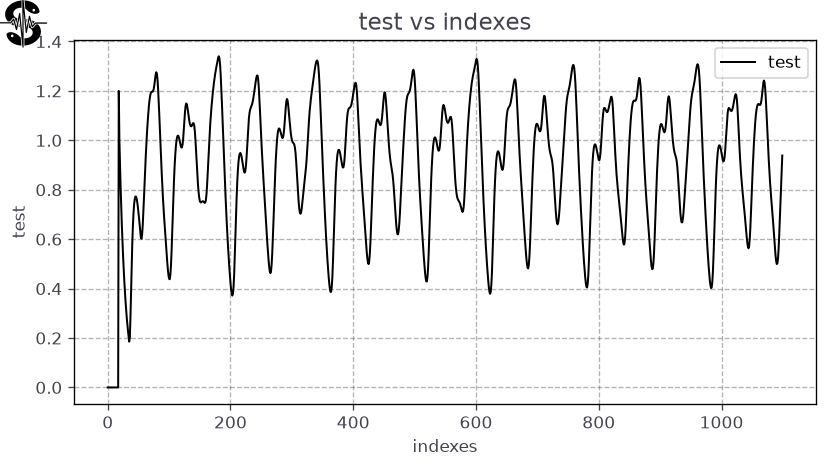

In [16]:
invpy.graph(index, t, "indexes", "test")

In [17]:
t_clean = t[18:] #Clean up from first 0 values

In [18]:
t_0 = np.asarray(t_clean[:-24])
t_6 = np.asarray(t_clean[6:-18])
t_12 = np.asarray(t_clean[12:-12])
t_18 = np.asarray(t_clean[18:-6])
t_24 = np.asarray(t_clean[24:])

In [19]:
df_4 = np.vstack((t_0, t_6, t_12, t_18, t_24)).T

In [20]:
val_perc = 15/100
test_perc = 15/85

df_train_4, df_test_4 = train_test_split(
        df_4,
        test_size=test_perc,
        shuffle=True,
        random_state=8,
    )

df_train_4, df_val_4 = train_test_split(
        df_train_4,
        test_size=val_perc,
        shuffle=True,
        random_state=8,
    )

In [21]:
df_train_4.shape

(740, 5)

In [22]:
class_list_4 = [False]*5
configs_4 = generate_configurations(class_list_4)
result_4 = paper_test(df_train_4, df_val_4, df_test_4, configs_4)

Starting optimizzation for:
 {'fire_of_train_rules': True, 'fuzzy_output': True, 'default_division': ['D', 'D', 'D', 'D', 'D'], 'task': 'regression'}
|----> Starting Global Optimization 
|----> New best score with n_of_sets: [5 5 5 5 5] -> Scored: 0.9573517895010795
|----> New best score with n_of_sets: [6 6 6 6 6] -> Scored: 0.9679778023304428
|----> New best score with n_of_sets: [7 7 7 7 7] -> Scored: 0.9746442433470275
|----> New best score with n_of_sets: [8 8 8 8 8] -> Scored: 0.9842149571089236
|----> New best score with n_of_sets: [9 9 9 9 9] -> Scored: 0.9863603350640573
|--------> Starting Coordinate-wise Optimization 
|--------> New best score with n_of_sets: [8 9 9 9 9] -> Scored: 0.9864973635114045
|--------> New best score with n_of_sets: [8 8 9 9 9] -> Scored: 0.9874878783235654
|--------> New best score with n_of_sets: [ 8  8  9 10  9] -> Scored: 0.987847424638689
|------------> Cross-validation ended succesfully:
|------------> [ 8  8  9 10  9] -> Best number of set pe

In [23]:
from_res_to_table(result_4)

,DB,ER,HF,r2,cov
0,D,ON,ON,0.99,0.99
1,D,ON,OFF,0.99,0.99
2,L,ON,ON,0.98,0.99
3,L,ON,OFF,0.97,1.00
4,L,OFF,OFF,0.97,1.00
5,D,OFF,ON,0.96,0.99
6,D,OFF,OFF,0.96,1.00
7,L,OFF,ON,0.95,1.00


In [24]:
mg_model = WEMDS(fire_of_train_rules=True, default_n_of_sets=[ 8,  8,  9, 10,  9])
mg_model.fit(df_train_4)

In [25]:
pred_4 = mg_model.predict(df_test_4[:,:-1])
y_tru_4 = df_test_4[:,-1]
time_4 = xp.arange(len(y_tru_4))

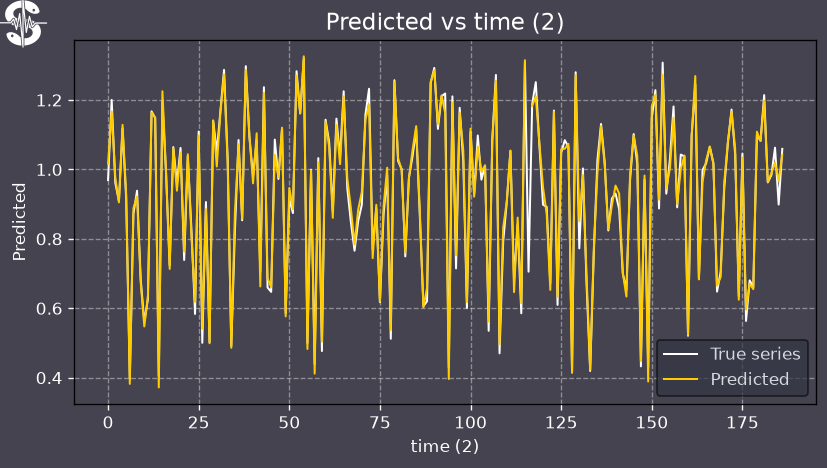

In [26]:
fig,ax = invpy.graph(time_4, y_tru_4, "time (2)", "True series", dark_mode=True)
_ = invpy.graph(time_4, pred_4, "time (2)", "Predicted", dark_mode=True, ax=ax)

In [29]:
mg_model.Rules.shape

(250, 6)